# Lab 12: CNN Feature Visualization, Parameter Audit, and Critical Analysis

This notebook runs in Google Colab without any external downloads. It generates a high-contrast architectural test image, applies five custom 3x3 filters across four CNN pipeline stages, plots the 5x4 feature map grid, and compares Model A (3x3, MaxPool) vs Model B (5x5, AvgPool).


In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

## Part I: Architectural Test Image and Custom 3x3 Filters


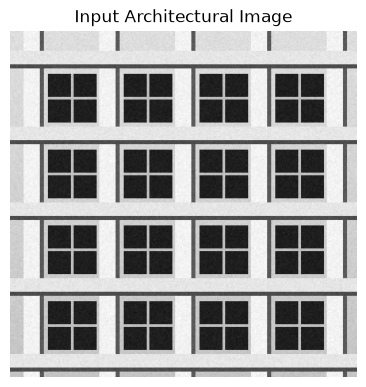

In [2]:
def create_architectural_test_image(size=256):
    img = np.full((size, size), 0.82, dtype=np.float32)
    grad = np.linspace(0.92, 0.72, size, dtype=np.float32)[:, None]
    img = img * 0.5 + grad * 0.5

    for x in [16, 72, 128, 184, 240]:
        img[:, max(0, x - 6):min(size, x + 6)] = 0.95
        img[:, max(0, x + 6):min(size, x + 9)] = 0.35

    for y in [20, 76, 132, 188, 244]:
        img[max(0, y - 5):min(size, y + 5), :] = 0.90
        img[max(0, y + 5):min(size, y + 8), :] = 0.30

    rows = [(32, 68), (88, 124), (144, 180), (200, 236)]
    cols = [(28, 64), (84, 120), (140, 176), (196, 232)]
    for r0, r1 in rows:
        for c0, c1 in cols:
            img[r0:r1, c0:c1] = 0.12
            mid_r = (r0 + r1) // 2
            mid_c = (c0 + c1) // 2
            img[mid_r - 1:mid_r + 1, c0:c1] = 0.75
            img[r0:r1, mid_c - 1:mid_c + 1] = 0.75

    rng = np.random.default_rng(42)
    noise = rng.normal(0.0, 0.015, size=(size, size)).astype(np.float32)
    return np.clip(img + noise, 0.0, 1.0)

img = create_architectural_test_image(256)
plt.figure(figsize=(4.5, 4.5))
plt.imshow(img, cmap="gray", vmin=0.0, vmax=1.0)
plt.title("Input Architectural Image")
plt.axis("off")
plt.show()

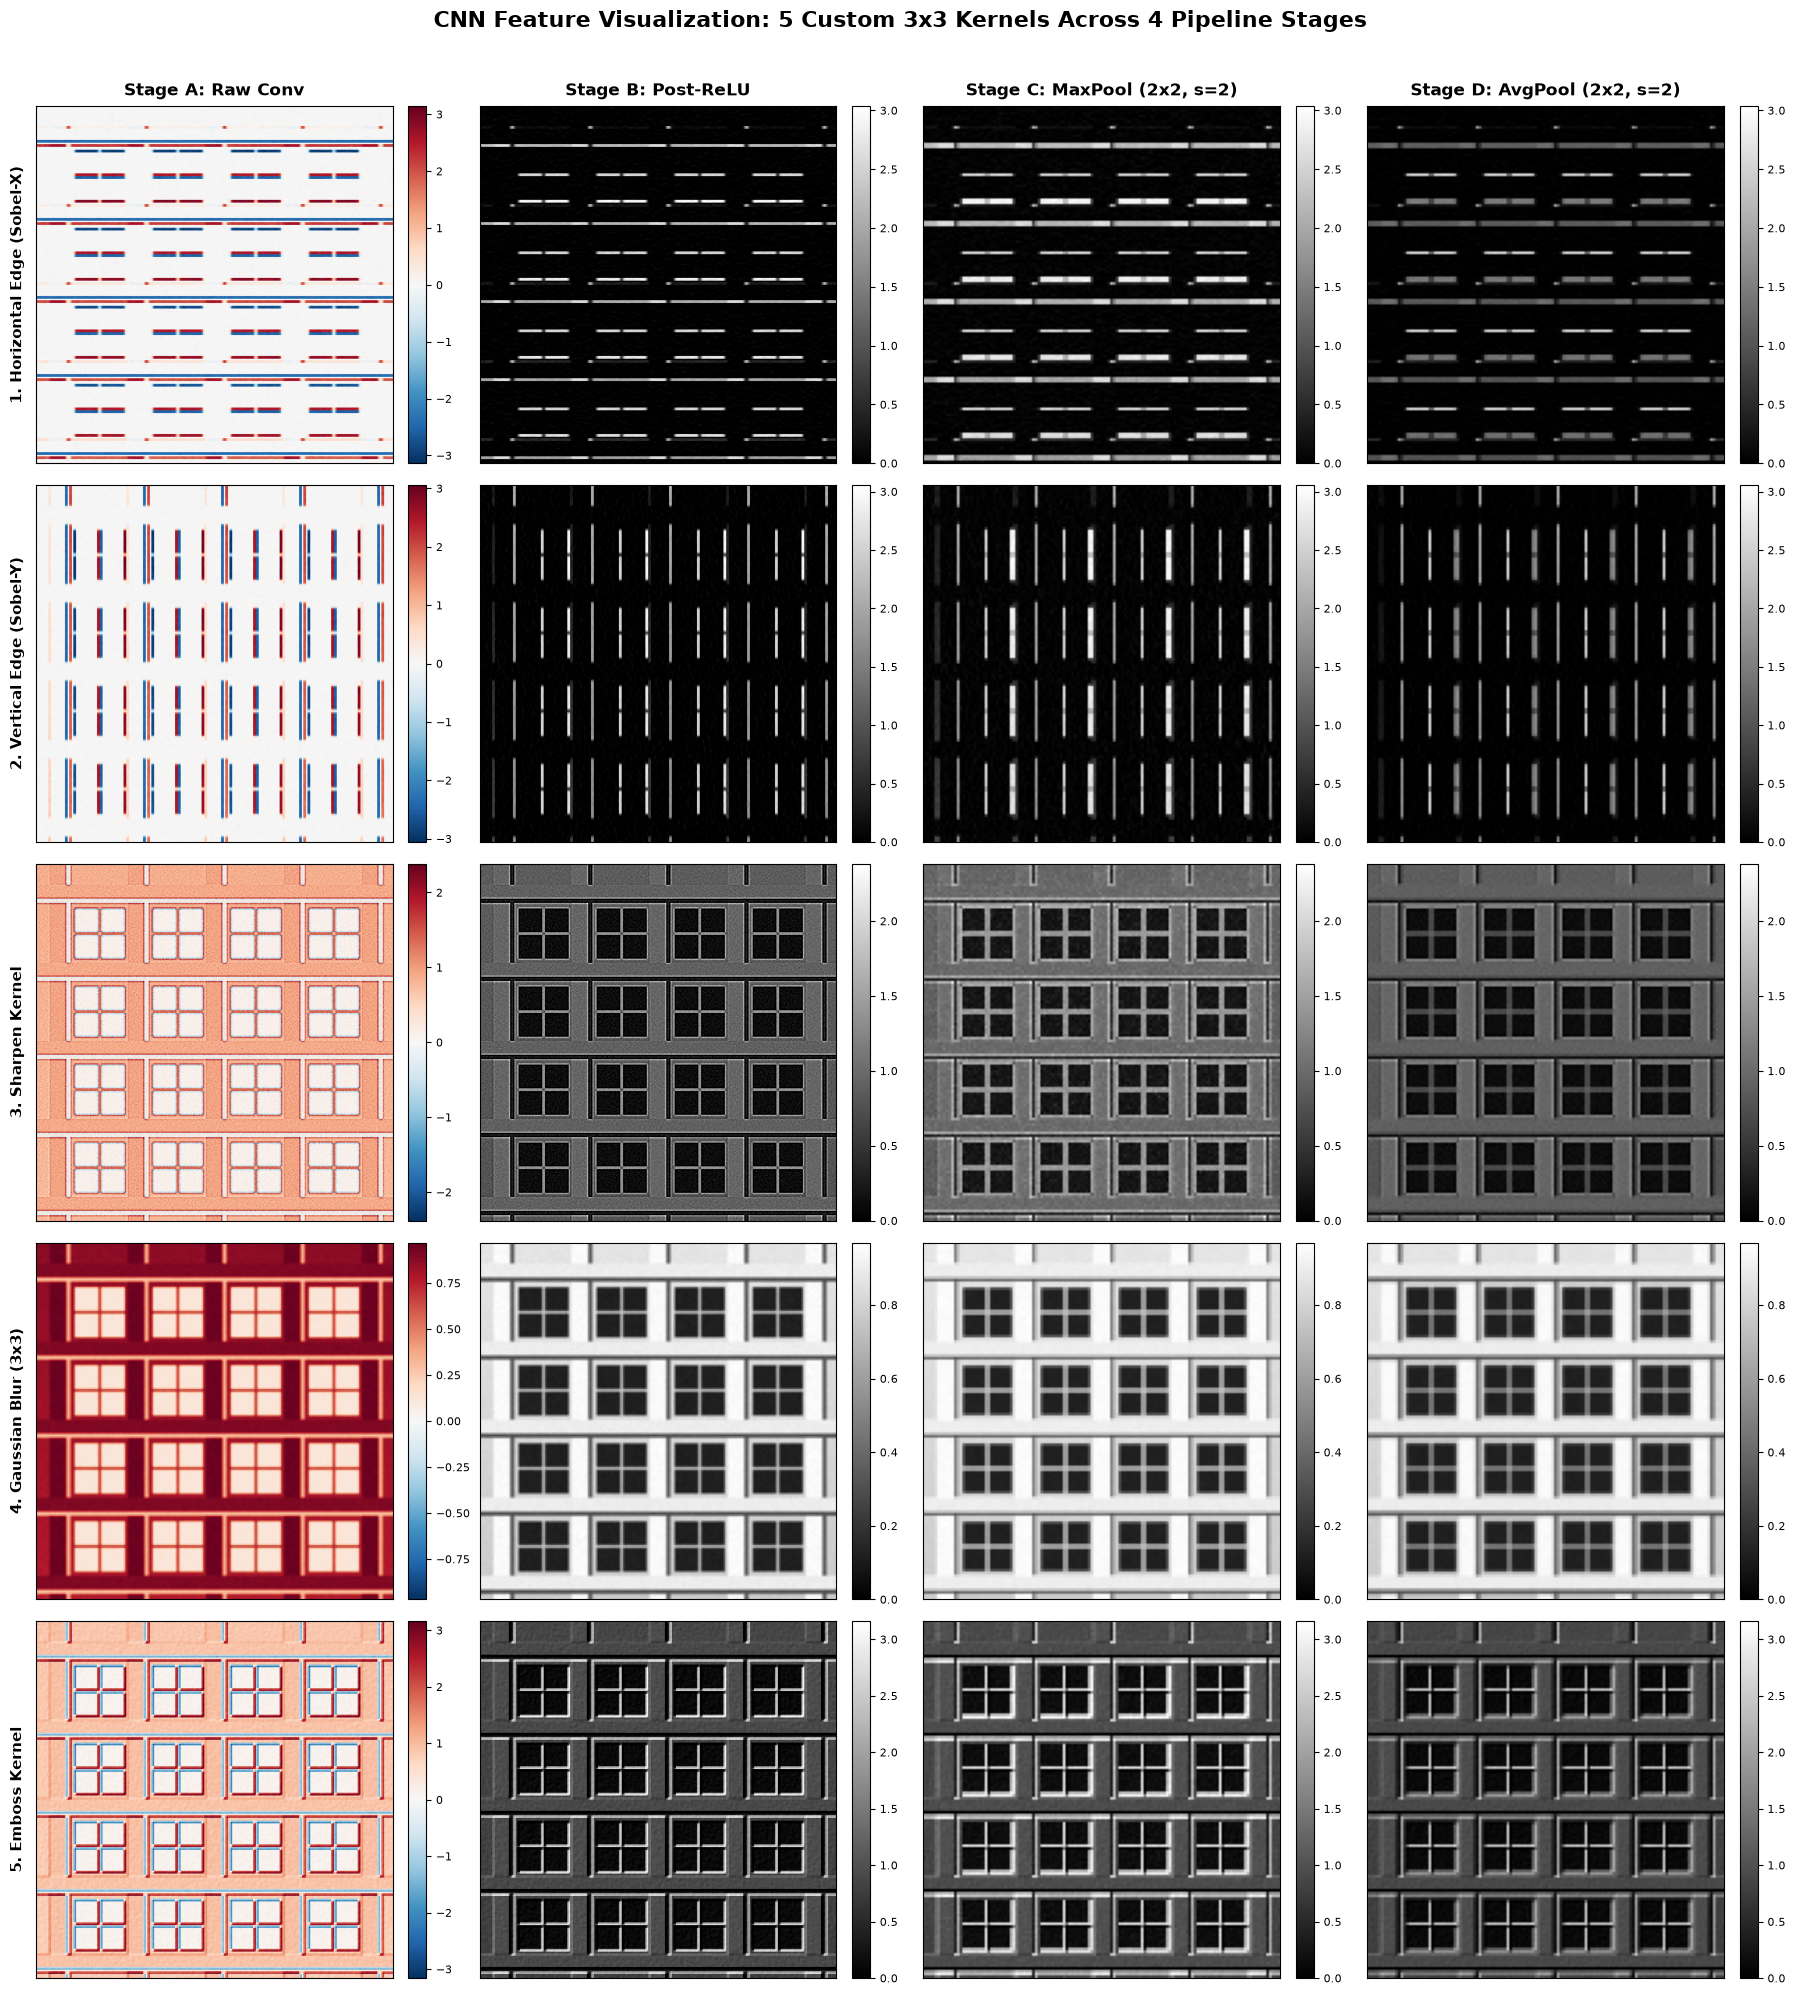

In [3]:
kernels = {
    "1. Horizontal Edge (Sobel-X)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32),
    "2. Vertical Edge (Sobel-Y)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32),
    "3. Sharpen Kernel": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32),
    "4. Gaussian Blur (3x3)": np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float32) / 16.0,
    "5. Emboss Kernel": np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]], dtype=np.float32),
}

def pool_2x2_stride2(feat, mode="max"):
    h, w = feat.shape
    h2, w2 = (h // 2) * 2, (w // 2) * 2
    blocks = feat[:h2, :w2].reshape(h2 // 2, 2, w2 // 2, 2)
    if mode == "max":
        return blocks.max(axis=(1, 3))
    return blocks.mean(axis=(1, 3))

stage_names = [
    "Stage A: Raw Conv",
    "Stage B: Post-ReLU",
    "Stage C: MaxPool (2x2, s=2)",
    "Stage D: AvgPool (2x2, s=2)",
]

fig, axes = plt.subplots(5, 4, figsize=(18, 20))
fig.suptitle("CNN Feature Visualization: 5 Custom 3x3 Kernels Across 4 Pipeline Stages", fontsize=16, fontweight="bold", y=0.995)

for row_idx, (k_name, kernel) in enumerate(kernels.items()):
    stage_a = cv2.filter2D(img, ddepth=cv2.CV_32F, kernel=kernel, borderType=cv2.BORDER_REPLICATE)
    stage_b = np.maximum(0.0, stage_a)
    stage_c = pool_2x2_stride2(stage_b, mode="max")
    stage_d = pool_2x2_stride2(stage_b, mode="avg")

    stages = [stage_a, stage_b, stage_c, stage_d]
    pos_vmax = max(float(stage_b.max()), 1e-5)
    raw_abs_max = max(abs(float(stage_a.min())), abs(float(stage_a.max())), 1e-5)

    for col_idx, feat in enumerate(stages):
        ax = axes[row_idx, col_idx]
        if col_idx == 0:
            im = ax.imshow(feat, cmap="RdBu_r", vmin=-raw_abs_max, vmax=raw_abs_max)
        else:
            im = ax.imshow(feat, cmap="gray", vmin=0.0, vmax=pos_vmax)
        if row_idx == 0:
            ax.set_title(stage_names[col_idx], fontsize=12, fontweight="bold", pad=8)
        if col_idx == 0:
            ax.set_ylabel(k_name, fontsize=10.5, fontweight="bold", labelpad=8)
        ax.set_xticks([])
        ax.set_yticks([])
        cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cbar.ax.tick_params(labelsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

## Part II: Model A (3x3, MaxPool) vs Model B (5x5, AvgPool) Parameter Audit


In [4]:
def build_cnn_model(name, kernel_size, pool_type):
    pool_layer = layers.MaxPooling2D if pool_type == "max" else layers.AveragePooling2D
    model = models.Sequential(name=name)
    model.add(layers.Input(shape=(32, 32, 3), name="input_rgb"))
    model.add(layers.Conv2D(5, (kernel_size, kernel_size), activation="relu", name="conv1"))
    model.add(pool_layer(pool_size=(2, 2), strides=2, name="pool1"))
    model.add(layers.Conv2D(10, (kernel_size, kernel_size), activation="relu", name="conv2"))
    model.add(pool_layer(pool_size=(2, 2), strides=2, name="pool2"))
    model.add(layers.GlobalAveragePooling2D(name="global_avg_pool"))
    model.add(layers.Dense(10, activation="softmax", name="output_dense"))
    return model

model_a = build_cnn_model("Model_A_Standard_3x3_MaxPool", kernel_size=3, pool_type="max")
model_b = build_cnn_model("Model_B_LargeKernel_5x5_AvgPool", kernel_size=5, pool_type="avg")

model_a.summary()
print()
model_b.summary()

pct_inc = (model_b.count_params() - model_a.count_params()) / model_a.count_params() * 100.0
print(f"Model A Total Parameters: {model_a.count_params()}")
print(f"Model B Total Parameters: {model_b.count_params()}")
print(f"Percentage Increase: {pct_inc:.2f}%")

Model: "Model_A_Standard_3x3_MaxPool"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 30, 30, 5)      │           140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 15, 15, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 13, 13, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 6, 6, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_dense (Dense)            │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710 (2.77 KB)

 Trainable params: 710 (2.77 KB)

 Non-trainable params: 0 (0.00 B)

Model: "Model_B_LargeKernel_5x5_AvgPool"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 28, 28, 5)      │           380 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (AveragePooling2D)        │ (None, 14, 14, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 10, 10, 10)     │         1,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (AveragePooling2D)        │ (None, 5, 5, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 10)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_dense (Dense)            │ (None, 10)             │           110 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,750 (6.84 KB)

 Trainable params: 1,750 (6.84 KB)

 Non-trainable params: 0 (0.00 B)

Model A Total Parameters: 710
Model B Total Parameters: 1750
Percentage Increase: 146.48%
